# 06 · Сжатие признаков и кластеризация КТГ

## tl;dr

Выполнены **55 представлений × 30 настроек = 1650 сочетаний**. UMAP: 27 вариантов; компактный denoising-автоэнкодер: 24; PCA: 3; без сжатия: 1. Все 9 прежних файлов кластеризации сохранены побайтно.

Выбор проводился без `NSP`/`CLASS`: средний по исходным файлам silhouette на validation в общем пространстве из 21 подготовленного столбца; проверки размера кластеров, сходимости и trustworthiness. Затем выполнены диагностика устойчивости и сопоставление с экспертной разметкой.

| Представление FCM | k | Test ARI с NSP | Test NMI |
|---|---:|---:|---:|
| Прежний PCA 90%, ноутбук 04 | 2 | 0.0741 | 0.1215 |
| RAW · новый протокол | 2 | 0.0764 | 0.1226 |
| PCA · новый протокол | 2 | 0.0483 | 0.1096 |
| UMAP · новый протокол | 2 | -0.0104 | 0.0730 |
| AE · новый протокол | 2 | 0.0641 | 0.0755 |

AE + GMM: test ARI **0.2159**; в наиболее обогащённом кластере патология у **44.4%** сегментов (20/45), но патологические случаи — всего из **2 исходных файлов**. Обогащение 5.40× с широким точечным интервалом 0.00–8.52. При двух дополнительных seed ARI назначений относительно основного решения всего -0.010–0.075: решение неустойчиво к инициализации. Этого недостаточно для подтверждения самостоятельной группы риска.

**Test уже просматривался в предыдущем исследовании.** Это исследовательское дополнение, а не новая слепая проверка и не доказательство клинических групп риска. Рост ARI на этом наборе не использован для изменения параметров или модели классификации.

## Context & Methods

Продолжение 04 с сохранением его результатов. Источник: UCI Cardiotocography, 2126 сегментов; разбиение по исходным файлам из 01 остаётся прежним. Цель — проверить, выявляет ли нелинейное сжатие воспроизводимые группы измерений и как они соотносятся с экспертной разметкой.

### Key Assumptions

- Идентификатора пациентки нет. Разделение, early stopping и bootstrap используют исходный файл как доступную единицу записи; это не доказывает независимость разных файлов одной женщины.
- Обучение всех преобразований и кластеров — только на train. Validation используется для выбора без меток; test только для последующего описания зафиксированных решений. Повторное использование уже просмотренного test делает анализ исследовательским.
- Вход: ровно 21 исходный признак. Преобразователь 01 клонируется и обучается заново; `DS` и `Width` исключаются по его контракту. Удаляются дублирующие индикаторы наличия редких значений. 18 числовых столбцов стандартизуются; 3 one-hot `Tendency` делятся на √2. Это 21 столбец расстояний, а не 21 независимая исходная переменная.
- Нули сохраняются. В исходном наборе нет пропусков; новый пропуск отклоняется входным контрактом. Метки, строки, имена файлов и даты не входят в матрицу. Идентификатор файла используется только для разбиения, усреднения и ресэмплинга.
- UMAP: `n_components={2,5,10}`, `n_neighbors={10,30,60}`, `min_dist={0,.1,.5}`, евклидова метрика, 300 эпох, фиксированный seed. Число компонент не ограничивается красивой двумерной картинкой. Validation/test преобразуются через `transform`, без повторного fit.
- Автоэнкодер: `21 → {16,32} → {2,5,10} → {16,32} → 21`, активация `tanh/relu`, линейный выход, `alpha={.001,.1}`. Adam, шаг .001, batch 128, гауссов шум .05 на входе, чистая цель реконструкции. Это компактный undercomplete denoising AE на sklearn MLPRegressor, без разметки и без огромной сети для малого набора.
- Early stopping: отдельные 20% исходных файлов внутри train; внутренние скейлеры обучены только на оставшихся файлах. Критерий — чистая реконструкция holdout, patience 60, максимум 1200 эпох, улучшение >1e−5. Затем AE заново обучается на полном исходном train ровно выбранное число эпох. Остановка на внешней validation/test запрещена. Пилот 300 эпох часто упирался в лимит: на одном варианте продолжение уменьшило holdout MSE с .2256 до .1927 (лучшая эпоха 750), поэтому бюджет расширен по реконструкции, без NSP. Достижение лимита эпох явно показано и не равнозначно доказанной сходимости.
- Контроль: PCA с {2,5,10} компонентами и без сжатия. Для всех представлений одна сетка кластеров: k=2..6; FCM m={1.5,2,2.5}; KMeans; GMM diag/full. Несколько инициализаций. Всего 55×30=1650 сочетаний; это полный перебор указанной сетки, не гарантия глобального оптимума.

### Выбор без экспертных классов

Основной критерий — silhouette **в общем пространстве подготовленных признаков**, сначала средний по сегментам каждого validation-файла, затем средний по файлам. Это снижает влияние записей с большим числом сегментов и позволяет сравнить разные сжатия в одной геометрии. Вложенный silhouette в латентном пространстве показан отдельно. Такая цель предпочитает глобально разделимые группы и может недооценивать сложные нелинейные формы; она не является универсальным определением «лучших кластеров».

Исключаются несошедшиеся/вырожденные решения, кластеры <3% train или validation, UMAP/AE/PCA с trustworthiness <.80 (10 соседей). Сохранение соседей показано дополнительно. При равенстве выбираются меньше компонент, меньше k, затем фиксированный ID. Внутри каждой пары «представление × алгоритм» остаётся один вариант. BIC сравним только для GMM в одном представлении, поэтому между сжатиями не оптимизируется.

После сохранения `locked_config.json`: ещё два seed и пять обучений на случайных 80% train-файлов с повторным fit всей подготовки. ARI назначений на одной и той же validation показывает чувствительность. По этим диагностическим результатам и по NSP повторного отбора нет.

UMAP способен искажать плотность и создавать ложные разрывы: [официальное руководство по кластеризации](https://umap-learn.readthedocs.io/en/latest/clustering.html). Индуктивное применение: [transform](https://umap-learn.readthedocs.io/en/latest/transform.html). Сеть и регуляризация: [MLPRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html). Качество локальных соседств: [trustworthiness](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.trustworthiness.html).

## Data

### 1. Окружение и источники

In [4]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.training.ctg_embeddings import (RESULTS, ARTIFACT, run_embeddings, legacy_snapshot,
    versions, project, CTG_FEATURES)
from src.training.ctg_experiments import load_data
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.02)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'RAW':'#6b7280', 'PCA':'#d97706', 'UMAP':'#0072b2', 'AE':'#009e73'}
def show_save(name):
    plt.gcf().savefig(RESULTS / name, dpi=150, bbox_inches='tight')
    plt.show()
data, source_fingerprint = load_data()
display(pd.Series(versions(), name='version').to_frame())
display(data.groupby('split').agg(segments=('source_file','size'), source_files=('source_file','nunique')))
print('Source fingerprint:', source_fingerprint)

Source fingerprint: f9c52010a79720e3324ce3e301e530240df3dfc32f44d6823e6a9e4974353060


,version
numpy,2.4.6
scipy,1.17.1
pandas,2.3.3
scikit-learn,1.9.1
umap-learn,0.5.12
numba,0.68.0
pynndescent,0.6.0
joblib,1.6.0


,segments,source_files
split,,
test,425,68
train,1360,227
validation,341,57


### 2. Выполнить полную сетку

Первый запуск обучает все варианты и диагностику устойчивости. Повторный использует checkpoint только при совпадении данных, кода и версий. Все старые файлы кластеризации проверяются по SHA-256.

In [6]:
receipt = run_embeddings()
display(pd.Series({k:v for k,v in receipt.items() if k in [
    'representations','joint_configurations','selected_models','legacy_unchanged',
    'early_stop_fit_files','early_stop_validation_files','elapsed_seconds']}).to_frame('value'))

Loaded complete, code/data/version-matched extension results.


,value
representations,55
joint_configurations,1650
selected_models,12
legacy_unchanged,True
early_stop_fit_files,181
early_stop_validation_files,46
elapsed_seconds,209.3636


## Results

### 3. Покрытие сетки и зафиксированные параметры

In [8]:
grid = pd.read_csv(RESULTS / 'joint_grid.csv')
embeddings = pd.read_csv(RESULTS / 'embedding_grid.csv')
chosen = pd.read_csv(RESULTS / 'chosen_configurations.csv')
association = pd.read_csv(RESULTS / 'association.csv')
risk = pd.read_csv(RESULTS / 'test_risk_summary.csv')
stability = pd.read_csv(RESULTS / 'stability.csv')
display(grid.groupby('method').agg(representations=('embedding_id','nunique'),
    combinations=('key','size'), eligible=('eligible','sum')))
selected = chosen.merge(embeddings[['embedding_id','params','best_epoch','hit_epoch_cap']], on='embedding_id')
selected['parameters'] = selected.params.map(lambda s: '; '.join(f'{k}={v}' for k,v in json.loads(s).items() if k!='n_components'))
display(selected[['method','algorithm','dimensions','k','variant','parameters']])
display(selected[['method','algorithm','validation_group_silhouette_common',
    'validation_silhouette_embedding','trustworthiness','neighbor_overlap',
    'best_epoch','hit_epoch_cap']].round(4))
print('Полная сетка:', RESULTS / 'joint_grid.csv')

Полная сетка: /Users/nick/Desktop/projects/femfedora/research/experiments/ctg_uci/embeddings/joint_grid.csv


,representations,combinations,eligible
method,,,
AE,24,720,652
PCA,3,90,81
RAW,1,30,22
UMAP,27,810,760


,method,algorithm,dimensions,k,variant,parameters
0,AE,FCM,2,2,1.5,activation=relu; alpha=0.001; width=16
1,AE,GMM,5,2,diag,activation=relu; alpha=0.1; width=16
2,AE,KMeans,2,2,NaN,activation=relu; alpha=0.001; width=16
3,PCA,FCM,2,2,1.5,
4,PCA,GMM,2,2,diag,
5,PCA,KMeans,2,2,NaN,
6,RAW,FCM,21,2,1.5,
7,RAW,GMM,21,2,diag,
8,RAW,KMeans,21,2,NaN,
9,UMAP,FCM,5,2,1.5,min_dist=0.1; n_neighbors=30


,method,algorithm,validation_group_silhouette_common,validation_silhouette_embedding,trustworthiness,neighbor_overlap,best_epoch,hit_epoch_cap
0,AE,FCM,0.2803,0.6617,0.9100,0.4282,842.0,False
1,AE,GMM,0.2974,0.4020,0.9593,0.5370,624.0,False
2,AE,KMeans,0.2803,0.6617,0.9100,0.4282,842.0,False
3,PCA,FCM,0.2579,0.4112,0.9122,0.4179,NaN,False
4,PCA,GMM,0.2560,0.4124,0.9122,0.4179,NaN,False
5,PCA,KMeans,0.2592,0.4155,0.9122,0.4179,NaN,False
6,RAW,FCM,0.2553,0.2407,1.0000,1.0000,NaN,False
7,RAW,GMM,0.2893,0.2722,1.0000,1.0000,NaN,False
8,RAW,KMeans,0.2541,0.2382,1.0000,1.0000,NaN,False
9,UMAP,FCM,0.2541,0.4696,0.9489,0.5147,NaN,False


### 4. Разделимость в латентном и общем пространствах

Каждая точка — лучший допустимый вариант кластеризации для одного представления. Диагональ — равенство двух silhouette; завышенная разделимость только после сжатия требует осторожности. Групповой критерий выбора отличается от обычного среднего по строкам, показанного по оси X.

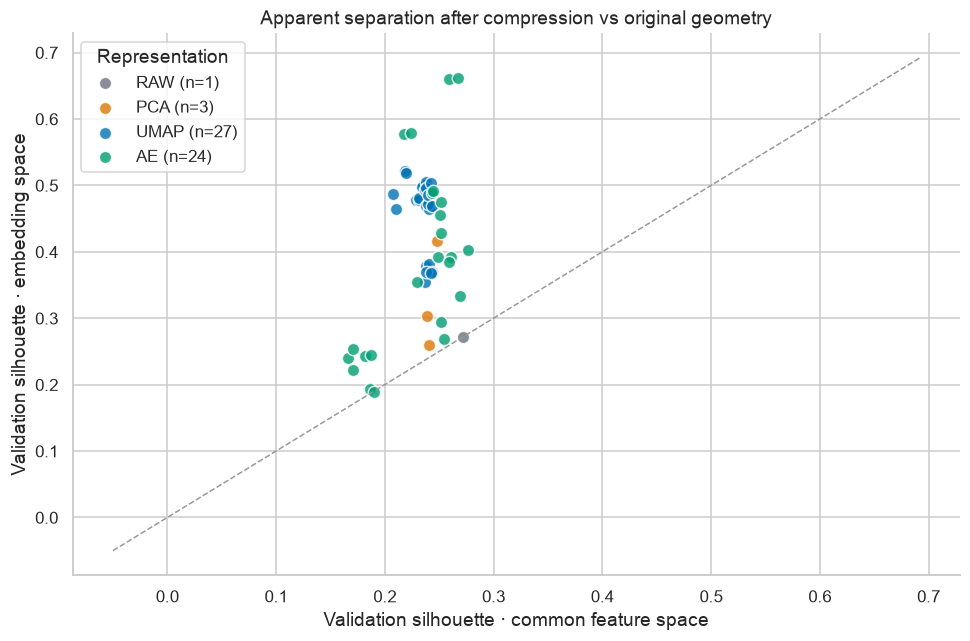

In [10]:
best_per_embedding = grid[grid.eligible].sort_values('validation_group_silhouette_common').groupby('embedding_id').tail(1)
fig, ax = plt.subplots(figsize=(9, 6))
for method in ['RAW','PCA','UMAP','AE']:
    part = best_per_embedding[best_per_embedding.method == method]
    ax.scatter(part.validation_silhouette_common, part.validation_silhouette_embedding,
        s=65, alpha=.8, color=COLORS[method], label=f'{method} (n={len(part)})', edgecolor='white')
limits = [-.05, max(.65, best_per_embedding.validation_silhouette_embedding.max()+.03)]
ax.plot(limits, limits, '--', color='.6', lw=1)
ax.set(xlabel='Validation silhouette · common feature space',
    ylabel='Validation silhouette · embedding space', title='Apparent separation after compression vs original geometry')
ax.legend(title='Representation'); fig.tight_layout()
show_save('01_geometry.png')

### 5. Реконструкция и остановка автоэнкодера

Ошибка — средний квадрат в общей шкале входа, включая кодированную Tendency; это не физические единицы КТГ. PCA служит линейным ориентиром. Внешняя validation-реконструкция приведена для диагностики и не заменяет основной критерий. Флаг лимита эпох означает, что больший бюджет обучения ещё мог бы изменить результат.

,variants,minimum_stop_mse,median_epochs,reached_cap,minimum_validation_mse
dimensions,,,,,
2,8,0.3935,539.5,0,0.3511
5,8,0.1837,696.0,2,0.1793
10,8,0.0495,814.5,2,0.0440


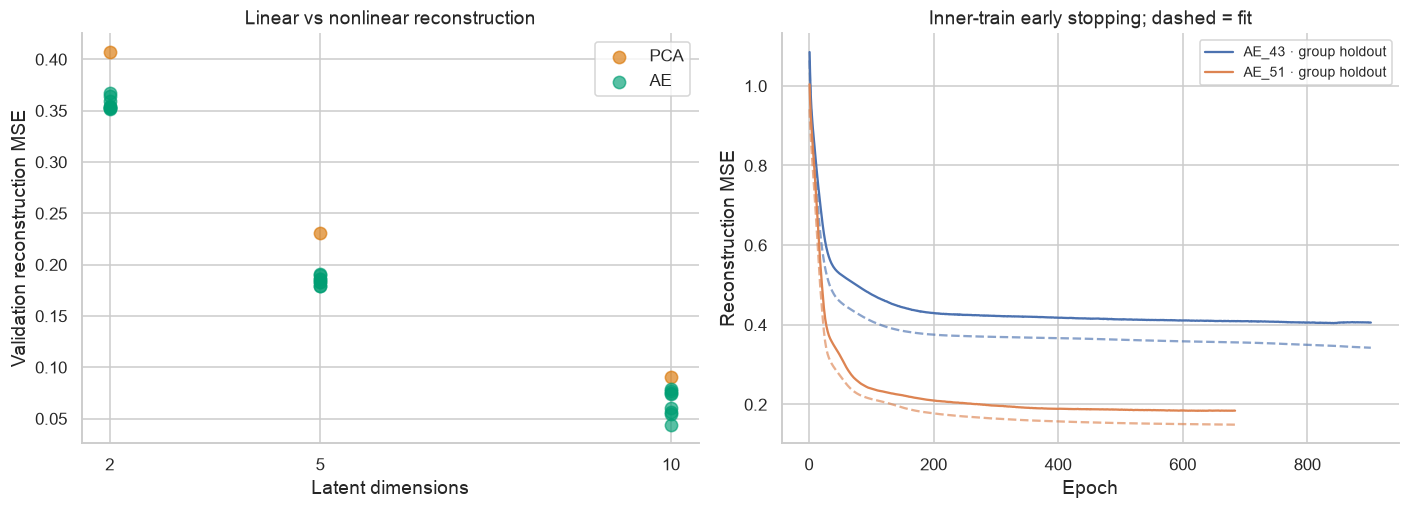

In [12]:
ae = embeddings[embeddings.method == 'AE']
display(ae.groupby(['dimensions','activation'] if 'activation' in ae else ['dimensions']).agg(
    variants=('embedding_id','size'), minimum_stop_mse=('stop_mse','min'),
    median_epochs=('best_epoch','median'), reached_cap=('hit_epoch_cap','sum'),
    minimum_validation_mse=('validation_reconstruction_mse','min')).round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for method in ['PCA','AE']:
    p = embeddings[embeddings.method == method]
    axes[0].scatter(p.dimensions, p.validation_reconstruction_mse, color=COLORS[method],
        s=65, alpha=.65, label=method)
axes[0].set(xlabel='Latent dimensions', ylabel='Validation reconstruction MSE', title='Linear vs nonlinear reconstruction')
axes[0].set_xticks([2,5,10]); axes[0].legend()
for eid in chosen.loc[chosen.method == 'AE','embedding_id'].unique():
    curve = pd.read_csv(RESULTS / f'{eid}_learning_curve.csv')
    line, = axes[1].plot(curve.epoch, curve.stop_mse, label=f'{eid} · group holdout')
    axes[1].plot(curve.epoch, curve.train_mse, '--', color=line.get_color(), alpha=.65)
axes[1].set(xlabel='Epoch', ylabel='Reconstruction MSE', title='Inner-train early stopping; dashed = fit')
axes[1].legend(fontsize=9); fig.tight_layout()
show_save('02_autoencoder.png')

### 6. Устойчивость зафиксированных решений

Сравниваются назначения на тех же validation-сегментах, ARI инвариантен к перестановке номеров кластеров. Все преобразования переобучаются в подвыборках файлов. Диапазоны по пяти подвыборкам — анализ чувствительности, не 95% интервалы. При смене seed меняются редуктор и инициализация кластеров; при подвыборке seed фиксирован.

mean    min    max
method algorithm mode                               
AE     FCM       file_subsample  0.673  0.475  0.795
                 seed            0.283  0.012  0.555
       GMM       file_subsample  0.278 -0.033  0.714
                 seed            0.032 -0.010  0.075
       KMeans    file_subsample  0.653  0.487  0.782
                 seed            0.281  0.009  0.553
PCA    FCM       file_subsample  0.931  0.908  0.953
                 seed            1.000  1.000  1.000
       GMM       file_subsample  0.873  0.737  0.977
                 seed            0.965  0.953  0.977
       KMeans    file_subsample  0.940  0.897  0.988
                 seed            0.994  0.988  1.000
RAW    FCM       file_subsample  0.938  0.842  0.977
                 seed            1.000  1.000  1.000
       GMM       file_subsample  0.852  0.675  0.987
                 seed            1.000  1.000  1.000
       KMeans    file_subsample  0.901  0.678  1.000
                 seed            1.000  1.000  1.000
UMAP   FCM       file_subsample  0.847  0.593  0.941
                 seed            0.930  0.918  0.941
       GMM       file_subsample  0.682  0.262  0.916
                 seed            0.935  0.894  0.976
       KMeans    file_subsample  0.835  0.557  0.941
                 seed            0.947  0.941  0.953

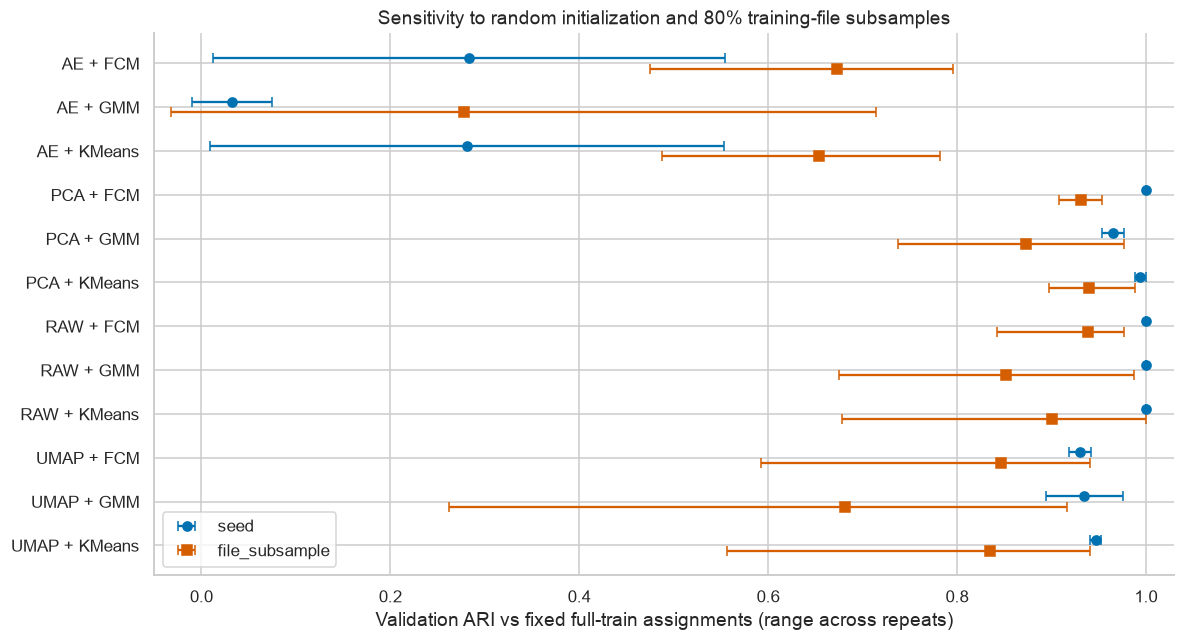

In [14]:
stability_summary = stability.groupby(['method','algorithm','mode']).validation_ari_vs_reference.agg(['mean','min','max'])
display(stability_summary.round(3))
fig, ax = plt.subplots(figsize=(11, 6))
labels = [f'{r.method} + {r.algorithm}' for r in chosen.itertuples()]
for shift, mode, marker, color in [(-.12,'seed','o','#0072b2'),(.12,'file_subsample','s','#d55e00')]:
    p = stability[stability['mode'] == mode].groupby('key').validation_ari_vs_reference.agg(['mean','min','max']).reindex(chosen.key)
    y = np.arange(len(p)) + shift
    ax.errorbar(p['mean'], y, xerr=np.vstack([p['mean']-p['min'],p['max']-p['mean']]),
        fmt=marker, color=color, capsize=3, label=mode)
ax.set_yticks(np.arange(len(labels)), labels); ax.invert_yaxis()
ax.set(xlabel='Validation ARI vs fixed full-train assignments (range across repeats)',
    title='Sensitivity to random initialization and 80% training-file subsamples', xlim=(-.05,1.03))
ax.legend(loc='lower left'); fig.tight_layout()
show_save('03_stability.png')

### 7. Сопоставление с NSP после фиксации

Сначала показан прежний результат 04, затем все 12 решений нового протокола. ARI/NMI не были критериями подбора. Новый PCA отличается от прежнего сеткой и способом выбора; сопоставление не изолирует только влияние метода сжатия.

,method,algorithm,k,ari,nmi
0,04 · PCA90,FCM,2,0.0741,0.1215
1,04 · PCA90,GMM,2,-0.0024,0.0535
2,04 · PCA90,KMeans,2,0.0913,0.1294
3,AE,FCM,2,0.0641,0.0755
4,AE,GMM,2,0.2159,0.1263
5,AE,KMeans,2,0.0641,0.0755
6,PCA,FCM,2,0.0483,0.1096
7,PCA,GMM,2,0.0717,0.1205
8,PCA,KMeans,2,0.0390,0.1051
9,RAW,FCM,2,0.0764,0.1226


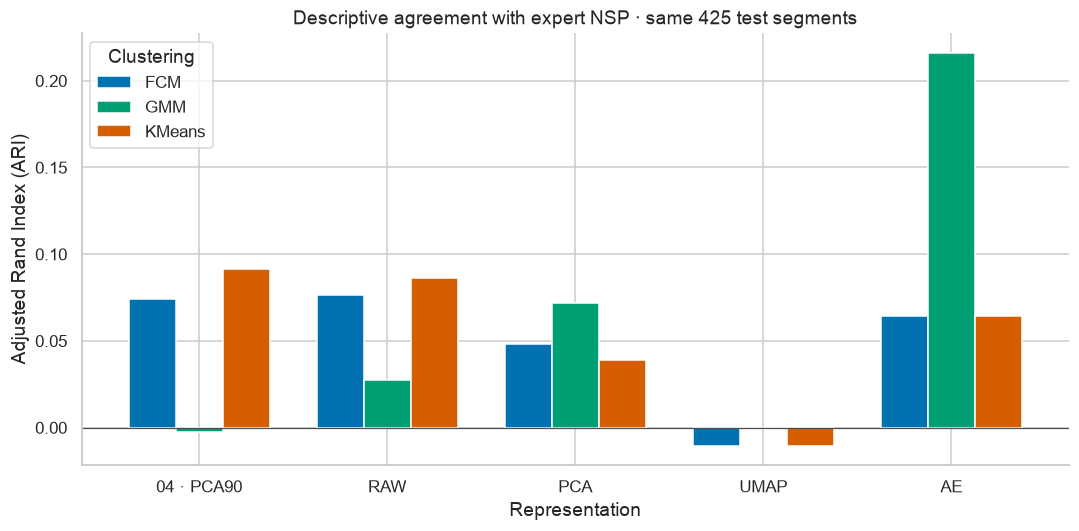

In [16]:
old_association = pd.read_csv(ROOT / 'research/experiments/ctg_uci/cluster_association.csv')
old_test = old_association[old_association.split == 'test'].copy()
old_test['method'] = '04 · PCA90'
new_test = association[association.split == 'test'].copy()
comparison = pd.concat([old_test[['method','algorithm','k','ari','nmi']],
    new_test[['method','algorithm','k','ari','nmi']]], ignore_index=True)
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(10,5))
table = comparison.pivot(index='method', columns='algorithm', values='ari').reindex(['04 · PCA90','RAW','PCA','UMAP','AE'])
table.plot.bar(ax=ax, color=['#0072b2','#009e73','#d55e00'], width=.75)
ax.axhline(0,color='.3',lw=.8); ax.set(title='Descriptive agreement with expert NSP · same 425 test segments',
    xlabel='Representation', ylabel='Adjusted Rand Index (ARI)')
ax.tick_params(axis='x', rotation=0); ax.legend(title='Clustering'); fig.tight_layout()
show_save('04_nsp_association.png')

### 8. Состав кластеров и интервалы обогащения

Основной фокус — патологический класс. Suspect и abnormal=NSP>1 приведены как описательное уточнение. Bootstrap: 1000 повторов по 68 исходным test-файлам, все сегменты выбранного файла остаются вместе. Интервалы точечные и не корректируются за 12 моделей и несколько кластеров/исходов. Малые числа патологических файлов ограничивают надёжность; отдельно показано число файлов с патологией внутри кластера. Принадлежности FCM и posterior GMM относятся к кластерам и не являются вероятностью клинического риска или класса NSP.

,method,algorithm,cluster,segments,source_files,pathological,path_source_files,limited_path_support,path_fraction
0,AE,FCM,0,86,19,21,3,True,0.2442
1,AE,FCM,1,339,60,14,7,False,0.0413
2,AE,GMM,0,45,10,20,2,True,0.4444
3,AE,GMM,1,380,65,15,8,False,0.0395
4,AE,KMeans,0,86,19,21,3,True,0.2442
5,AE,KMeans,1,339,60,14,7,False,0.0413
6,PCA,FCM,0,214,47,14,7,False,0.0654
7,PCA,FCM,1,211,41,21,3,True,0.0995
8,PCA,GMM,0,222,42,21,3,True,0.0946
9,PCA,GMM,1,203,46,14,7,False,0.0690


,method,algorithm,cluster,path_enrichment,path_enrichment_low,path_enrichment_high,suspect_fraction,abnormal_fraction
0,AE,FCM,0,2.9651,0.0000,4.5391,0.0349,0.2791
1,AE,FCM,1,0.5015,0.1737,1.1222,0.1622,0.2035
2,AE,GMM,0,5.3968,0.0000,8.5188,0.1111,0.5556
3,AE,GMM,1,0.4793,0.1767,1.0602,0.1395,0.1789
4,AE,KMeans,0,2.9651,0.0000,4.5391,0.0349,0.2791
5,AE,KMeans,1,0.5015,0.1737,1.1222,0.1622,0.2035
6,PCA,FCM,0,0.7944,0.2764,1.8245,0.2570,0.3224
7,PCA,FCM,1,1.2085,0.0000,1.7442,0.0142,0.1137
8,PCA,GMM,0,1.1486,0.0000,1.6632,0.0135,0.1081
9,PCA,GMM,1,0.8374,0.2928,1.9017,0.2709,0.3399


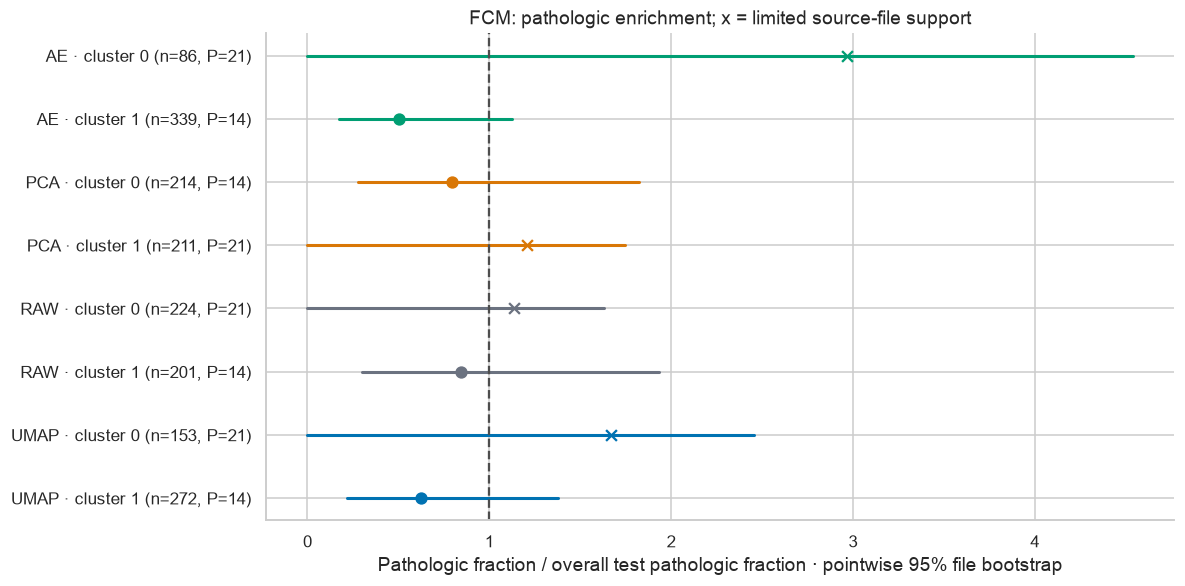

In [18]:
all_assignments = pd.read_parquet(RESULTS / 'assignments.parquet')
path_files = all_assignments[(all_assignments.split=='test') & (all_assignments.NSP==3)].groupby(['key','cluster']).source_file.nunique().rename('path_source_files')
risk = risk.merge(path_files,on=['key','cluster'],how='left')
risk['path_source_files'] = risk.path_source_files.fillna(0).astype(int)
risk['limited_path_support'] = risk.small_cluster | (risk.path_source_files < 5)
risk.to_csv(RESULTS / 'test_risk_summary_with_support.csv',index=False)
display(risk[['method','algorithm','cluster','segments','source_files','pathological','path_source_files',
    'limited_path_support','path_fraction']].round(4))
display(risk[['method','algorithm','cluster','path_enrichment','path_enrichment_low',
    'path_enrichment_high','suspect_fraction','abnormal_fraction']].round(4))
fcm_risk = risk[risk.algorithm == 'FCM'].copy()
fig, ax = plt.subplots(figsize=(11,5.5))
for i, row in enumerate(fcm_risk.itertuples()):
    ax.plot([row.path_enrichment_low,row.path_enrichment_high],[i,i],color=COLORS[row.method],lw=2)
    ax.scatter(row.path_enrichment,i,color=COLORS[row.method],s=50,marker='x' if row.limited_path_support else 'o')
ax.set_yticks(np.arange(len(fcm_risk)), [f'{r.method} · cluster {r.cluster} (n={r.segments}, P={r.pathological})' for r in fcm_risk.itertuples()])
ax.axvline(1,color='.3',ls='--'); ax.invert_yaxis()
ax.set(xlabel='Pathologic fraction / overall test pathologic fraction · pointwise 95% file bootstrap',
    title='FCM: pathologic enrichment; x = limited source-file support')
fig.tight_layout(); show_save('05_pathologic_enrichment.png')

### 9. Двумерные проекции FCM

Слева номера кластеров, справа экспертная разметка тех же test-сегментов. Для представления размерности >2 это дополнительная PCA-проекция, обученная на его train; для двумерного — сами координаты. Оси и расстояния между разными строками несопоставимы. Цвета NSP используются только для просмотра после фиксации; плотные островки UMAP не следует автоматически считать рисками.

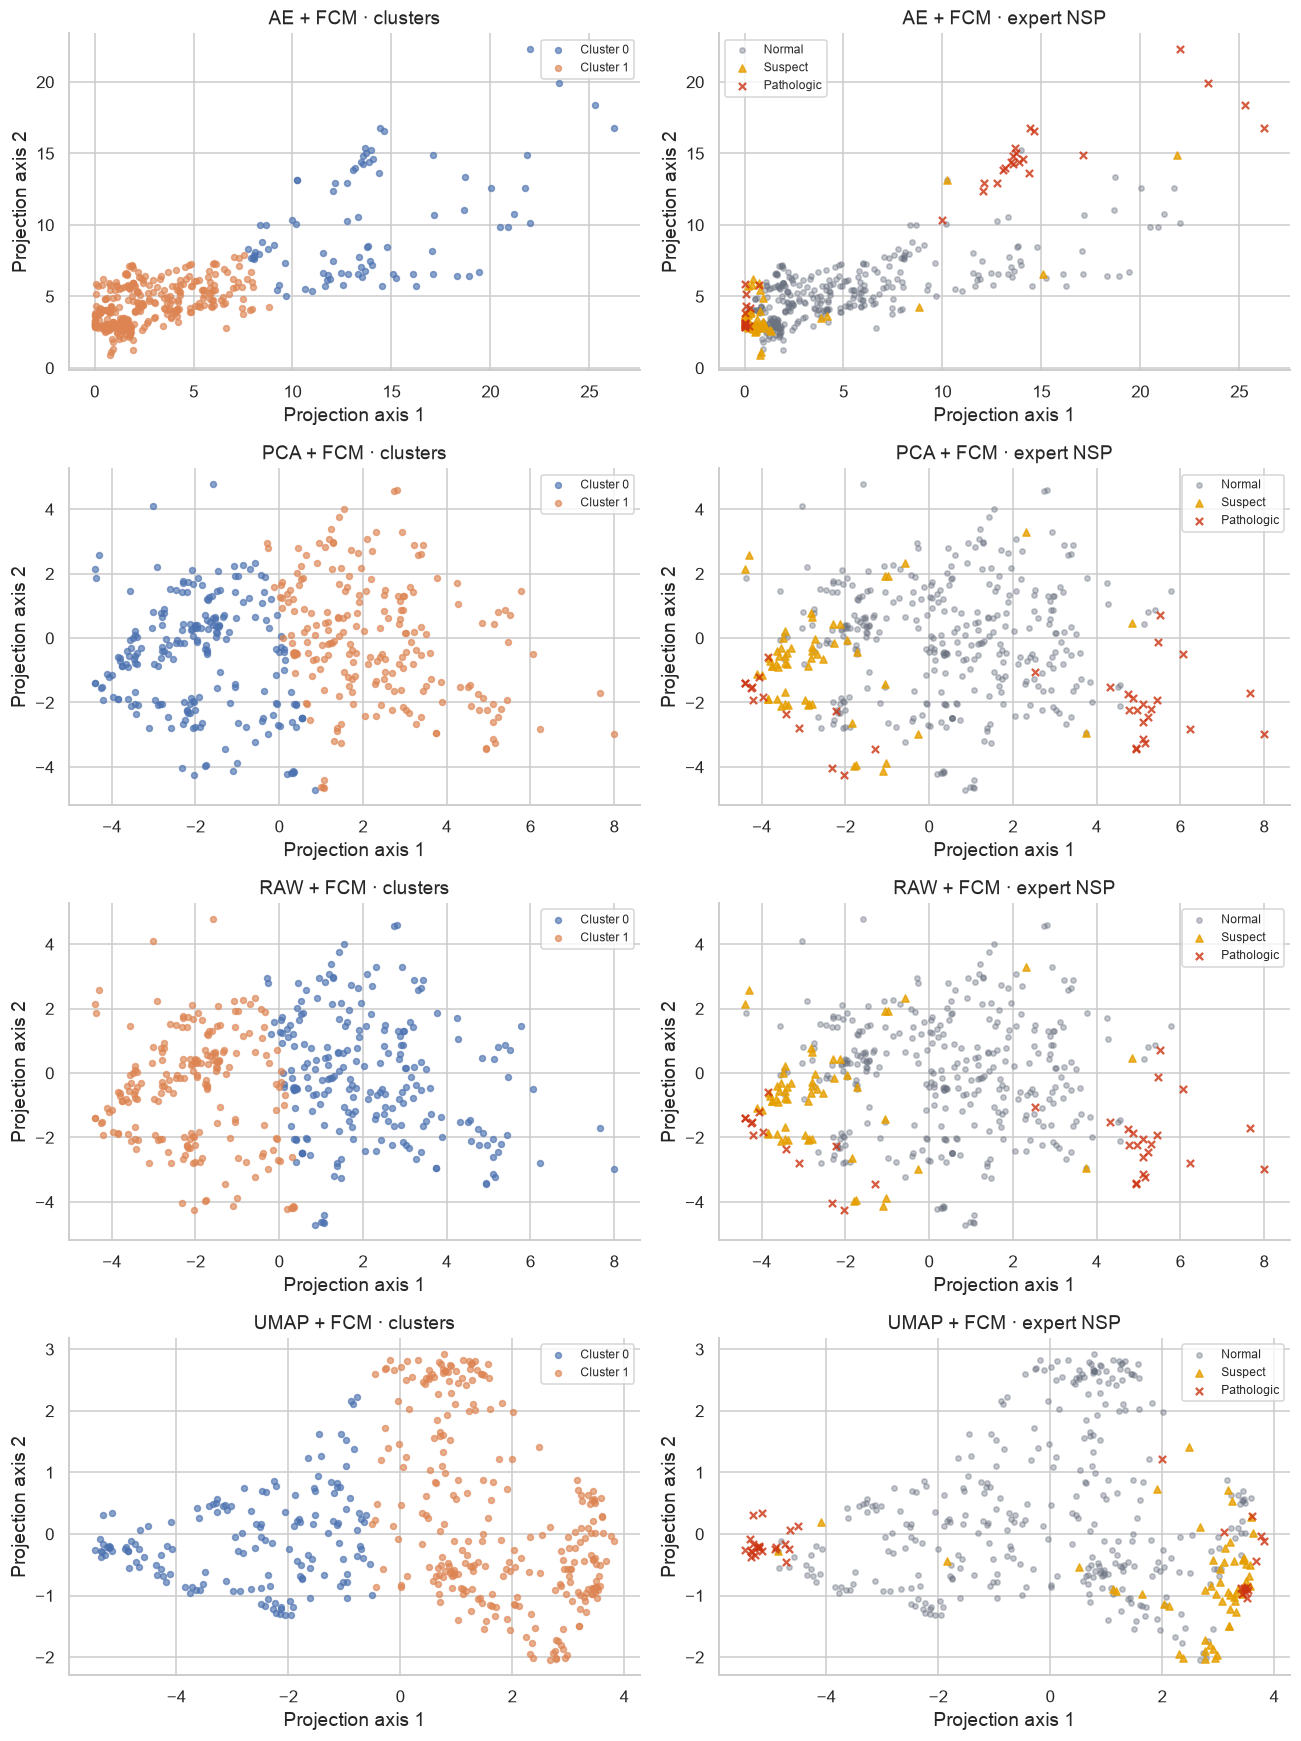

In [20]:
projections = pd.read_parquet(RESULTS / 'test_projections.parquet')
fcm_models = chosen[chosen.algorithm == 'FCM']
fig, axes = plt.subplots(4,2,figsize=(12,16))
for i, row in enumerate(fcm_models.itertuples()):
    p = projections[projections.key == row.key]
    for c in sorted(p.cluster.unique()):
        q=p[p.cluster == c]
        axes[i,0].scatter(q.axis1,q.axis2,s=15,alpha=.65,label=f'Cluster {c}')
    for label, color, marker, name in [(1,'#6b7280','o','Normal'),(2,'#e69f00','^','Suspect'),(3,'#cc3311','x','Pathologic')]:
        q=p[p.NSP == label]
        axes[i,1].scatter(q.axis1,q.axis2,s=22 if label>1 else 12,alpha=.8 if label>1 else .4,
            color=color,marker=marker,label=name)
    for j in range(2):
        axes[i,j].set(title=f'{row.method} + FCM · '+('clusters' if j==0 else 'expert NSP'),xlabel='Projection axis 1',ylabel='Projection axis 2')
        axes[i,j].legend(fontsize=8)
fig.tight_layout(); show_save('06_fcm_projections.png')

### 10. Независимые проверки сохранённых артефактов

Проверки не используют обучающие функции повторно: сопоставляют назначения со входными данными, пересчитывают ARI, состав кластеров, сумму принадлежностей и прогноз загруженного bundle. Отдельно контролируются группы early stopping и контрольные суммы 04.

In [22]:
saved = joblib.load(ARTIFACT)
assignments = pd.read_parquet(RESULTS / 'assignments.parquet')
preserved = json.loads((RESULTS / 'preserved_legacy.json').read_text())['sha256']
assert legacy_snapshot() == preserved
assert len(grid) == 1650 and len(embeddings) == 55 and len(chosen) == 12
assert len(assignments) == len(data) * 12
roles = pd.read_csv(RESULTS / 'ae_early_stopping_groups.csv')
assert roles.groupby('source_file').role.nunique().max() == 1
assert set(roles.source_excel_row) == set(data.loc[data.split=='train','source_excel_row'])
from sklearn.metrics import adjusted_rand_score
checks = 0
test = data[data.split=='test'].reset_index(drop=True)
common_test = saved['input_model'].transform(test[list(CTG_FEATURES)])
for row in chosen.itertuples():
    bundle = saved['bundles'][row.key]
    p = assignments[(assignments.key == row.key) & (assignments.split == 'test')].set_index('source_excel_row').loc[test.source_excel_row]
    assert np.array_equal(p.NSP.to_numpy(),test.NSP.to_numpy())
    memberships = p[[c for c in p if c.startswith('membership_') and c != 'membership_entropy']].fillna(0).to_numpy()
    np.testing.assert_allclose(memberships.sum(axis=1),1,atol=1e-7)
    assert np.array_equal(memberships.argmax(axis=1),p.cluster)
    predicted = bundle['clusterer'].predict(project(bundle['reducer'],common_test))
    assert np.array_equal(predicted,p.cluster)
    expected = association[(association.key == row.key) & (association.split == 'test')].iloc[0]
    assert abs(adjusted_rand_score(test.NSP,p.cluster)-expected.ari)<1e-12
    for cluster, q in p.groupby('cluster'):
        r = risk[(risk.key==row.key) & (risk.cluster==cluster)].iloc[0]
        assert len(q)==r.segments and int((q.NSP==3).sum())==r.pathological
        assert abs((q.NSP==3).mean()-r.path_fraction)<1e-12
    checks += 1
print(f'Проверены {checks} bundle, принадлежности и ARI; 55 представлений; 1650 комбинаций; старые файлы не изменились.')
print('Полные модели со скейлерами:', ARTIFACT)
print('Таблицы, параметры и рисунки:', RESULTS)

Проверены 12 bundle, принадлежности и ARI; 55 представлений; 1650 комбинаций; старые файлы не изменились.
Полные модели со скейлерами: /Users/nick/Desktop/projects/femfedora/models/exported/ctg_uci/clustering_embeddings.joblib
Таблицы, параметры и рисунки: /Users/nick/Desktop/projects/femfedora/research/experiments/ctg_uci/embeddings


## Takeaways

1. Сохранены исходные результаты 04; новые варианты находятся в отдельной папке `embeddings/`.
2. Подбор оценивает общую геометрию, а не только расстояния, искажённые сжатием. Сильный silhouette в UMAP сам по себе не доказывает наличие естественных групп.
3. ARI/NMI и состав кластеров — последующее сопоставление с экспертным классом. Ни число кластеров, ни сеть, ни UMAP по этим значениям не подбирались.
4. Интервалы обогащения точечные, по исходным файлам, без поправки на множественные сравнения; их следует рассматривать как гипотезы для независимого набора. NSP — экспертная интерпретация КТГ, не исход ребёнка.
5. Сохранены входной преобразователь со скейлерами, редукторы, веса автоэнкодеров, модели кластеров, все параметры сетки, кривые обучения, роли записей при early stopping, назначения и принадлежности.

**Ни у одного выбранного кластера точечный интервал обогащения патологией не лежит целиком выше 1.** В наиболее обогащённой группе AE+GMM файлов с патологией: 2; высокая доля сегментов не превращает их в множество независимых клинических наблюдений.

AE+GMM чувствителен к инициализации: ARI совпадения validation-назначений при двух дополнительных seed -0.010–0.075. Более высокий описательный ARI с NSP на одном test не делает этот вариант устойчивым победителем.

- UMAP+FCM: общий validation silhouette по файлам **0.254**; trustworthiness **0.949**; ARI устойчивости при 80% файлов **0.593–0.941**. Это чувствительность фиксированных параметров, не доверительный интервал.
- AE+FCM: общий validation silhouette по файлам **0.280**; trustworthiness **0.910**; ARI устойчивости при 80% файлов **0.475–0.795**. Это чувствительность фиксированных параметров, не доверительный интервал.